In [1]:
import csv
import biom
from biom import Table
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score

In [132]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import r2_score, mean_absolute_error

In [2]:
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")

In [3]:
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)

In [4]:
metadata.columns

Index(['bioproject_id', 'sample_id', 'subject_id', 'chim_perc', 'asv_count',
       'total_reads', 'study_cr_retention_rate', 'Observed', 'Shannon',
       'Simpson', 'InvSimpson', 'Chao1', 'age', 'age_info', 'bmi', 'sex',
       'platform', 'sequencing_region', 'pcr_primers', 'country', 'site',
       'site_group', 'disease_study', 'status', 'title', 'public_time',
       'matched_samples', 'is_time_series', 'age_cleaned', 'bmi_cleaned',
       'age_cleaned_group', 'age_info_cleaned', 'bmi_cleaned_group',
       'sex_cleaned', 'platform_cleaned', 'sequencing_region_cleaned',
       'country_cleaned', 'continent_group', 'site_cleaned',
       'site_group_cleaned', 'disease_study_cleaned', 'status_cleaned',
       'asv_le_30', 'study_asv_lt30_high', 'chim_gt_25',
       'study_chim_gt25_high', 'study_cr_retention_low'],
      dtype='object')

In [5]:
metadata = metadata.loc[metadata.age_cleaned > 0]
metadata = metadata.loc[metadata['site'].notna()]
metadata = metadata.loc[metadata.site_cleaned != "other"]

In [6]:
metadata.shape

(20078, 47)

In [7]:
metadata.site_cleaned.unique()

array(['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva'],
      dtype=object)

In [8]:
metadata.groupby("site_cleaned").count()

,bioproject_id,sample_id,subject_id,chim_perc,asv_count,total_reads,study_cr_retention_rate,Observed,Shannon,Simpson,...,country_cleaned,continent_group,site_group_cleaned,disease_study_cleaned,status_cleaned,asv_le_30,study_asv_lt30_high,chim_gt_25,study_chim_gt25_high,study_cr_retention_low
site_cleaned,,,,,,,,,,,,,,,,,,,,,
gingiva,104,104,104,104,104,104,104,104,104,104,...,104,104,104,104,104,104,104,104,104,104
oral mucosa,1147,1147,1147,1147,1147,1147,1147,1147,1147,1147,...,1147,1147,1147,1147,1116,1147,1147,1147,1147,1147
oral swab,2941,2941,2941,2941,2941,2941,2941,2941,2941,2941,...,2941,2941,2941,2841,2841,2941,2941,2941,2941,2941
saliva,13559,13559,13559,13559,13559,13559,13559,13559,13559,13559,...,13444,13444,13559,13559,12368,13559,13559,13559,13559,13559
tongue,360,360,360,359,360,360,360,360,360,360,...,360,360,360,360,357,360,360,359,360,360
tooth,1967,1967,1967,1967,1967,1967,1967,1967,1967,1967,...,1967,1967,1967,1967,1936,1967,1967,1967,1967,1967


In [9]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva']
for i in oral_sites:
    temp = metadata.loc[metadata.site_cleaned.values == i]
    print(len(temp.bioproject_id.unique()))

79
23
15
14
6
4


### RF difference sites

In [10]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva']
fold_test_studies = {
    'saliva': 10, 'tooth': 10, 'tongue': 5,
    'oral mucosa': 5, 'oral swab': 6, 'gingiva': 4
}

OUTPUT_DIR = "../../data/age_prediction/leave_studies_out"
sid_to_age = metadata.set_index('sample_id')['age_cleaned']

records = []

for j in oral_sites:
    metadata_pick = metadata.loc[metadata.site_cleaned == j]
    studies = metadata_pick.bioproject_id.unique()
    n_studies = len(studies)

    kf = KFold(n_splits=fold_test_studies[j], shuffle=True, random_state=42)

    for fold, (train_idx, test_idx) in enumerate(kf.split(studies), start=1):
        # ── 1. Split metadata by study ─────────────────────────────
        train_studies = studies[train_idx]
        test_studies  = studies[test_idx]

        md_train = metadata_pick.loc[[i in train_studies for i in metadata_pick.bioproject_id.values]]
        md_test  = metadata_pick.loc[[i in test_studies  for i in metadata_pick.bioproject_id.values]]

        # ── 2. Filter test set to training age range ───────────────
        age_min, age_max = md_train.age_cleaned.min(), md_train.age_cleaned.max()
        n_test_before = md_test.shape[0]
        md_test = md_test.loc[
            (md_test.age_cleaned > age_min) & (md_test.age_cleaned < age_max)
        ]
        n_test_after = md_test.shape[0]

        records.append({
            'site':             j,
            'fold':             fold,
            'n_studies':        n_studies,
            'n_train':          md_train.shape[0],
            'n_test_before':    n_test_before,
            'n_test_after':     n_test_after,
            'train/test ratio': round(md_train.shape[0] / n_test_after, 4) if n_test_after > 0 else None,
        })

        if n_test_after == 0:
            print(f"[SKIP] {j} fold {fold}: test set is empty after age filtering")
            continue

        # ── 3. Filter biom table ───────────────────────────────────
        train_table = table.filter(md_train.sample_id.values, inplace=False)
        train_table = train_table.remove_empty(inplace=False)  # remove all-zero OTUs

        # keep only OTUs present in training set to avoid dimension mismatch
        keep_otus = train_table.ids(axis='observation')
        test_table = table.filter(md_test.sample_id.values, inplace=False)
        test_table = test_table.filter(keep_otus, axis='observation', inplace=False)

        # ── 4. Normalize to relative abundance ────────────────────
        train_df = train_table.norm(axis='sample', inplace=False).to_dataframe(dense=True).T
        test_df  = test_table.norm(axis='sample', inplace=False).to_dataframe(dense=True).T

        # ── 5. Align OTU columns, fill missing with 0 ─────────────
        test_df = test_df.reindex(columns=train_df.columns, fill_value=0)

        # ── 6. Extract labels aligned to DataFrame row order ──────
        train_label = sid_to_age.reindex(train_df.index).values
        test_label  = sid_to_age.reindex(test_df.index).values

        # ── 7. Train RF model and predict ─────────────────────────
        rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
        rf.fit(train_df.values, train_label)
        pred_age = rf.predict(test_df.values)

        # ── 8. Save predictions ────────────────────────────────────
        site_tag = j.replace(' ', '_')
        result_df = pd.DataFrame({
            'sample_id': test_df.index,
            'true_age':  test_label,
            'pred_age':  pred_age,
            'error':     pred_age - test_label,
        })
        result_df.to_csv(f"{OUTPUT_DIR}/age_predict_test_{fold}_{site_tag}.csv", index=False)
        print(f"[OK] {j} fold {fold:2d} | train={md_train.shape[0]:4d}  test={n_test_after:3d}")

# ── Save summary table ─────────────────────────────────────────────
df_results = pd.DataFrame(records)
df_results.to_csv(f"{OUTPUT_DIR}/site_study_split_results.csv", index=False)
print(df_results.to_string(index=False))

[OK] saliva fold  1 | train=7122  test=6437


[OK] saliva fold  2 | train=12575  test=984


[OK] saliva fold  3 | train=12648  test=911


[OK] saliva fold  4 | train=11924  test=1635


[OK] saliva fold  5 | train=12572  test=707


...

[OK] oral swab fold  6 | train=2896  test= 45


[OK] gingiva fold  1 | train= 102  test=  2


[OK] gingiva fold  2 | train=  95  test=  9


[OK] gingiva fold  3 | train= 102  test=  1


[OK] gingiva fold  4 | train=  13  test= 31
       site  fold  n_studies  n_train  n_test_before  n_test_after  train/test ratio
     saliva     1         79     7122           6437          6437            1.1064
     saliva     2         79    12575            984           984           12.7795
     saliva     3         79    12648            911           911           13.8836
     saliva     4         79    11924           1635          1635            7.2930
     saliva     5         79    12572            987           707           17.7822
     saliva     6         79    13125            434           434           30.2419
     saliva     7         79    12610            949           949           13.2877
     saliva     8         79    12982            577           577           22.4991
     saliva     9         79    13269            290           290           45.7552
     saliva    10         79    13204            355           355           37.1944
      tooth     1    

### plot results

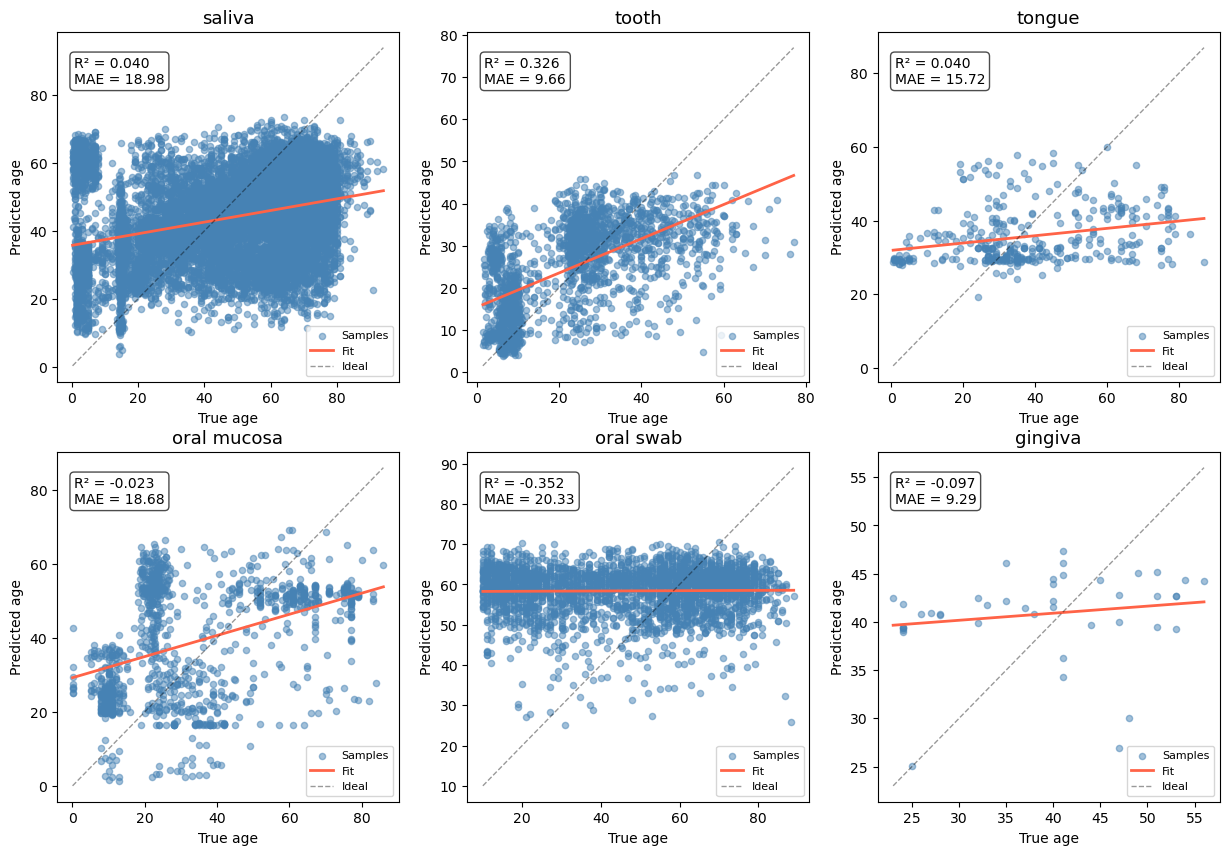

In [136]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva']
fold_test_studies = {
    'saliva': 10, 'tooth': 10, 'tongue': 5,
    'oral mucosa': 5, 'oral swab': 6, 'gingiva': 4
}
OUTPUT_DIR = "../../data/age_prediction/leave_studies_out"

site_dfs = {}
for j in oral_sites:
    site_tag = j.replace(' ', '_')
    dfs = [pd.read_csv(f"{OUTPUT_DIR}/age_predict_test_{i}_{site_tag}.csv")
           for i in range(1, fold_test_studies[j] + 1)]
    site_dfs[j] = pd.concat(dfs, ignore_index=True)

n = len(oral_sites)
ncols = 3
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 10))
axes = axes.flatten()

for idx, j in enumerate(oral_sites):
    ax = axes[idx]
    df = site_dfs[j]

    x = df['true_age'].values
    y = df['pred_age'].values

    r2  = r2_score(x, y)
    mae = mean_absolute_error(x, y)

    ax.scatter(x, y, alpha=0.5, s=20, color='steelblue', label='Samples')

    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    x_line = np.linspace(x.min(), x.max(), 200)
    ax.plot(x_line, p(x_line), color='tomato', linewidth=2, label='Fit')

    age_min = min(x.min(), y.min())
    age_max = max(x.max(), y.max())
    ax.plot([age_min, age_max], [age_min, age_max], 'k--', linewidth=1, alpha=0.4, label='Ideal')

    ax.set_title(j, fontsize=13)
    ax.set_xlabel('True age')
    ax.set_ylabel('Predicted age')
    ax.text(0.05, 0.93, f'R² = {r2:.3f}\nMAE = {mae:.2f}',
            transform=ax.transAxes, fontsize=10,
            verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
    ax.legend(fontsize=8, loc='lower right')

for idx in range(len(oral_sites), len(axes)):
    axes[idx].set_visible(False)

plt.show()

/home/dongbiao/.conda/envs/jupyter_notebook/lib/python3.9/site-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


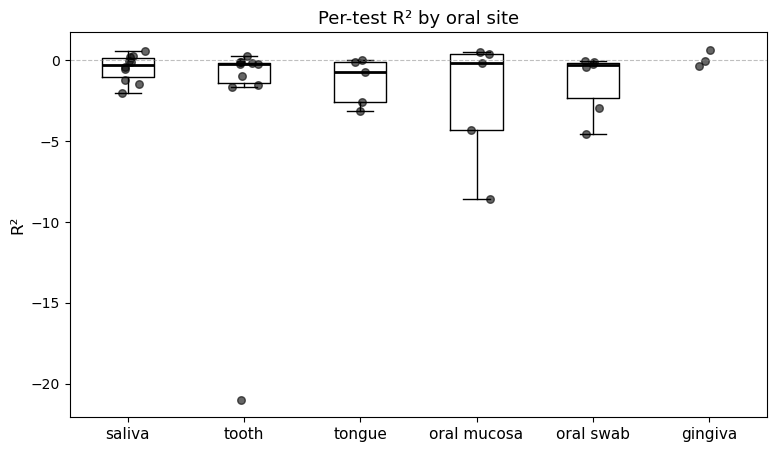

In [145]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva']
fold_test_studies = {
    'saliva': 10, 'tooth': 10, 'tongue': 5,
    'oral mucosa': 5, 'oral swab': 6, 'gingiva': 4
}
OUTPUT_DIR = "../../data/age_prediction/leave_studies_out"

site_r2s = {}
for j in oral_sites:
    site_tag = j.replace(' ', '_')
    r2_list = []
    for i in range(1, fold_test_studies[j] + 1):
        df = pd.read_csv(f"{OUTPUT_DIR}/age_predict_test_{i}_{site_tag}.csv")
        r2_list.append(r2_score(df['true_age'], df['pred_age']))
    site_r2s[j] = r2_list

fig, ax = plt.subplots(figsize=(9, 5))

data = [site_r2s[j] for j in oral_sites]
bp = ax.boxplot(data, patch_artist=False, widths=0.45,
                medianprops=dict(color='black', linewidth=2), showfliers=False)

for i, j in enumerate(oral_sites):
    x_vals = np.random.normal(i + 1, 0.06, size=len(site_r2s[j]))
    ax.scatter(x_vals, site_r2s[j], color='black', s=30, alpha=0.6)

ax.set_xticks(range(1, len(oral_sites) + 1))
ax.set_xticklabels(oral_sites, fontsize=11)
ax.set_ylabel('R²', fontsize=12)
ax.set_title('Per-test R² by oral site', fontsize=13)
ax.axhline(0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)

plt.show()

### Health and disease

In [195]:
metadata = metadata.loc[metadata['status_cleaned'].notna()]
metadata = metadata.loc[metadata.status_cleaned != "Other"]

In [196]:
metadata.status_cleaned.unique()

array(['HC', 'IBD', 'HIV', 'ICU', 'Obesity', 'OSCC', 'Atopic Dermatitis',
       'Chagas Disease', 'Oral Potentially Malignant Disorders',
       'Oral Mucositis', 'Preterm', 'Periodontal Disease',
       'Dental Caries', 'Celiac Disease', 'Sjögren’s Syndrome',
       'Pancreatic Cancer', 'Cancer', 'Aphthous',
       'Gastroesophageal Reflux Disease', 'COVID-19', 'Lung Cancer',
       'CRC', 'Axial Spondyloarthritis', 'Head and Neck Cancer',
       'Depression'], dtype=object)

In [ ]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva']
site_dfs = {}
for j in oral_sites:
    site_tag = j.replace(' ', '_')
    dfs = [pd.read_csv(f"{OUTPUT_DIR}/age_predict_test_{i}_{site_tag}.csv")
           for i in range(1, fold_test_studies[j] + 1)]
    site_dfs[j] = pd.concat(dfs, ignore_index=True).set_index("sample_id")

for idx, j in enumerate(oral_sites):
    
    metadata_pick = metadata.loc[metadata.site_cleaned == j]
    metadata_pick = metadata_pick.set_index("sample_id")
    inter_sid = np.intersect1d(metadata_pick.index.values, site_dfs[j].index.values)
    df = site_dfs[j].loc[inter_sid]
    df.loc[:, "status_cleaned"] = metadata_pick.loc[inter_sid, "status_cleaned"].values
    df.loc[:, "MAD"] = df.pred_age.values - df.true_age.values

### saliva

In [202]:
inter_sid = np.intersect1d(metadata_pick.index.values, site_dfs['saliva'].index.values)

In [212]:
df = site_dfs['saliva'].loc[inter_sid]

In [214]:
df.loc[:, "status_cleaned"] = metadata_pick.loc[inter_sid, "status_cleaned"].values

In [216]:
df.loc[:, "MAD"] = df.pred_age.values - df.true_age.values

In [217]:
df.status_cleaned.unique()

array(['HC', 'Obesity', 'Depression', 'HIV', 'IBD', 'ICU', 'OSCC',
       'Oral Mucositis', 'Oral Potentially Malignant Disorders',
       'Periodontal Disease', 'Dental Caries',
       'Gastroesophageal Reflux Disease', 'COVID-19', 'Lung Cancer',
       'Axial Spondyloarthritis', 'Head and Neck Cancer', 'CRC',
       'Celiac Disease', 'Pancreatic Cancer', 'Cancer'], dtype=object)

In [218]:
df

,true_age,pred_age,error,status_cleaned,MAD
sample_id,,,,,
11259.PHT.20.010.Cort.1900,31.0,30.942753,-0.057247,HC,-0.057247
11259.PHT.20.018.Cort.1600,29.0,35.903624,6.903624,HC,6.903624
11259.PHT.20.023.Cort.1000,49.0,40.073136,-8.926864,Obesity,-8.926864
11259.PHT.20.033.Cort.Waking,50.0,40.831221,-9.168779,HC,-9.168779
11259.PHT.20.036.Cort.Waking,49.0,30.293659,-18.706341,HC,-18.706341
...,...,...,...,...,...
SRR9955242,30.0,40.826867,10.826867,HC,10.826867
SRR9955243,36.0,45.480707,9.480707,HC,9.480707
SRR9955244,44.0,40.859025,-3.140975,HC,-3.140975


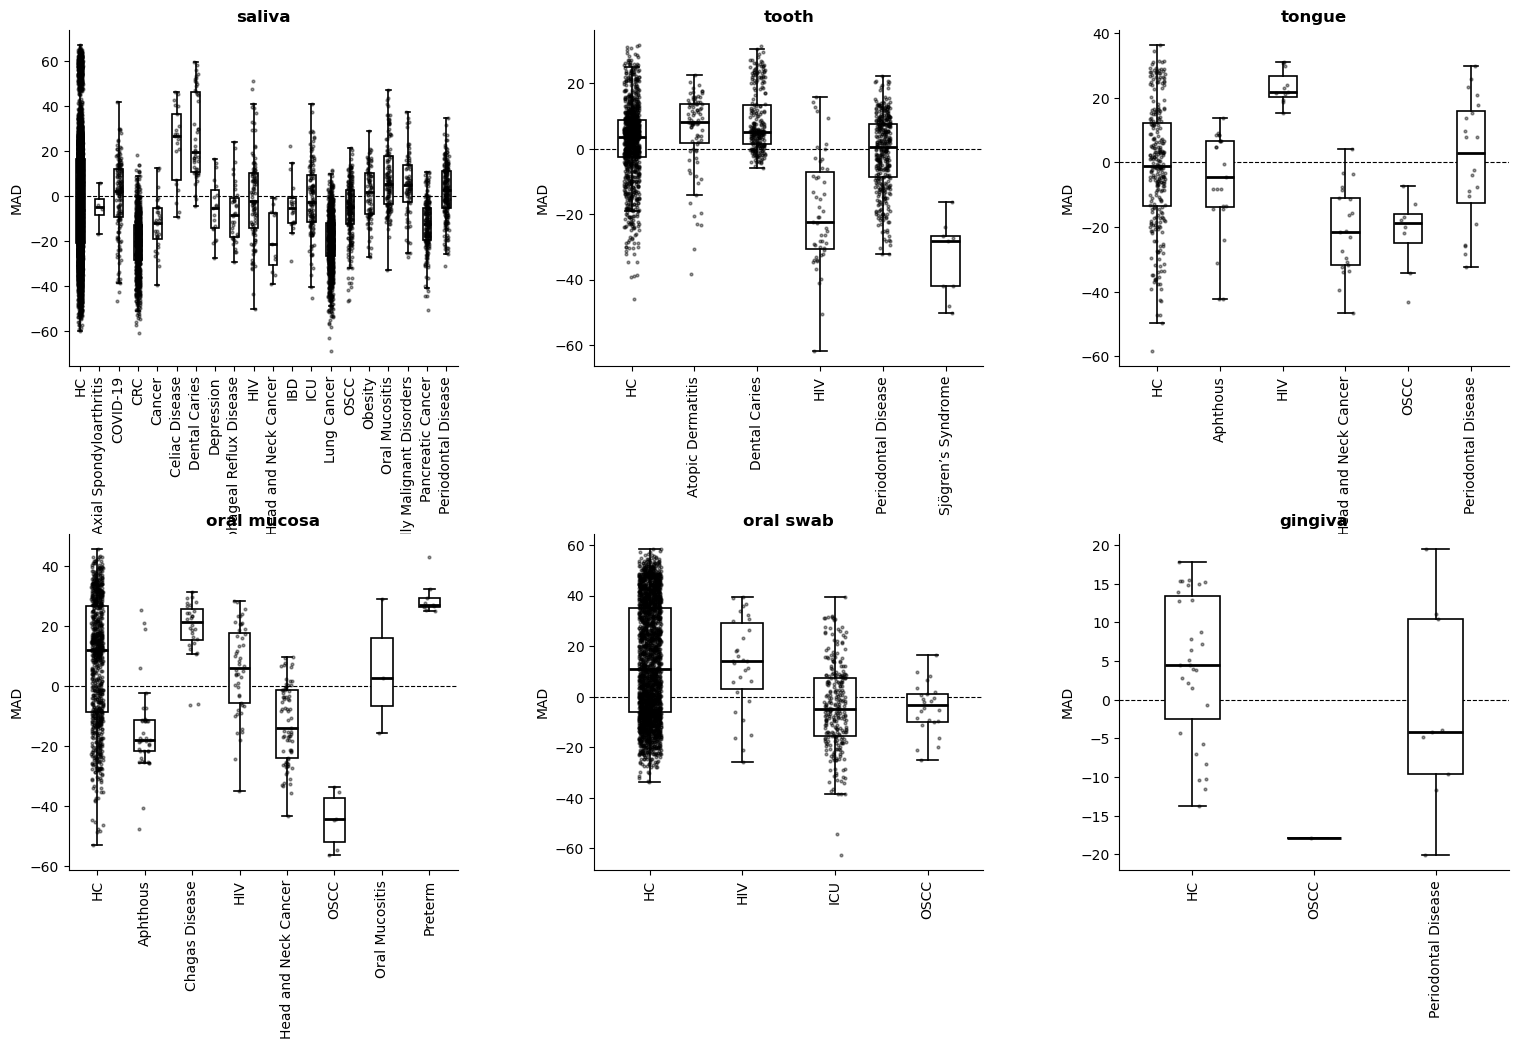

In [221]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec

def plot_one(ax, df, title):
    unique = df['status_cleaned'].unique()
    order  = ['HC'] + sorted([s for s in unique if s != 'HC'])

    positions = np.arange(1, len(order) + 1)
    box_data  = [df.loc[df['status_cleaned'] == s, 'MAD'].values for s in order]

    bp = ax.boxplot(
        box_data,
        positions    = positions,
        widths       = 0.45,
        patch_artist = True,
        showfliers   = False,
        medianprops  = dict(color='black', linewidth=2),
        whiskerprops = dict(linewidth=1.2, color='black'),
        capprops     = dict(linewidth=1.2, color='black'),
        boxprops     = dict(linewidth=1.2),
    )
    for patch in bp['boxes']:
        patch.set_facecolor('white')
        patch.set_edgecolor('black')

    for pos, s in zip(positions, order):
        y = df.loc[df['status_cleaned'] == s, 'MAD'].values
        x = np.random.uniform(pos - 0.12, pos + 0.12, size=len(y))
        ax.scatter(x, y, color='black', alpha=0.4, s=4, zorder=3)

    ax.axhline(0, color='black', linewidth=0.8, linestyle='--', zorder=1)
    ax.set_xticks(positions)
    ax.set_xticklabels(order, fontsize=10, rotation=90, ha='center')
    ax.set_ylabel('MAD', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=6)
    ax.set_xlim(0.4, len(order) + 0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


datasets = []
titles   = []
for j in oral_sites:
    metadata_pick = metadata.loc[metadata.site_cleaned == j].set_index("sample_id")
    inter_sid = np.intersect1d(metadata_pick.index.values, site_dfs[j].index.values)
    df = site_dfs[j].loc[inter_sid].copy()
    df["status_cleaned"] = metadata_pick.loc[inter_sid, "status_cleaned"].values
    df["MAD"] = df.pred_age.values - df.true_age.values
    datasets.append(df)
    titles.append(j)

fig = plt.figure(figsize=(16, 10))
gs  = GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.35,
               left=0.07, right=0.97, top=0.92, bottom=0.08)

for idx, (df, title) in enumerate(zip(datasets, titles)):
    row, col = divmod(idx, 3)
    ax = fig.add_subplot(gs[row, col])
    plot_one(ax, df, title)

plt.show()